# AWS(자동기상관측) 시간자료 — EDA · 전처리 · 특징 엔지니어링

**데이터**: `OBS_AWS_250712.csv` — 지점별 시간 단위 기상 관측값 (기온, 풍향, 풍속, 강수량, 현지/해면기압, 습도)

| 단계 | 내용 |
|---|---|
| 1. 로드 & 개요 | 인코딩(cp949) 처리, 컬럼 정리, 기본 통계 |
| 2. 데이터 품질 점검 | 결측, 센티널 값(-99), 풍향 0 문제, 시간축 연속성, 물리적 일관성 |
| 3. 기초 정제 | 센티널→결측, 풍향 처리, 지점×시간 격자 완성 |
| 4. EDA 시각화 | 분포, 시계열, 일주기, 강수, 바람장미, 상관, 지점 특성 |
| 5. 결측·이상치 처리 | 단기 보간, 기압 복원(지점 간 추정), 범위/급변/고정값 점검 |
| 6. 특징 엔지니어링 | 시간·물리·바람·기압/기온 변화·강수 누적 등 |
| 7. 검증 & 저장 | 최종 점검, 시간 기반 분할 + 스케일링 예시, 저장 |
| 8. 주요 인사이트 | 핵심 발견과 후속 분석 제안 |

## 0. 환경 설정

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager as fm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")

# 한글 폰트: OS별 후보 중 설치된 첫 번째를 사용
_installed = {f.name for f in fm.fontManager.ttflist}
for _font in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans KR", "Noto Sans CJK JP"]:
    if _font in _installed:
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100
print("font:", plt.rcParams["font.family"])

font: ['AppleGothic']


## 1. 데이터 로드 및 개요

In [4]:
DATA_PATH = "OBS_AWS_250712.csv"   # 필요하면 경로를 수정하세요

def read_csv_kr(path):
    """한글 CSV 인코딩 자동 판별 (utf-8-sig → cp949 → euc-kr)"""
    for enc in ("utf-8-sig", "cp949", "euc-kr"):
        try:
            return pd.read_csv(path, encoding=enc), enc
        except UnicodeDecodeError:
            continue
    raise ValueError("인코딩을 판별하지 못했습니다.")

raw, enc = read_csv_kr(f'../data/{DATA_PATH}')
print(f"인코딩: {enc} | shape: {raw.shape}")
raw.head()

인코딩: cp949 | shape: (505276, 10)


,지점,지점명,일시,기온(°C),풍향(deg),풍속(m/s),강수량(mm),현지기압(hPa),해면기압(hPa),습도(%)
0,310,궁촌,2025-07-01 00:00,24.800,0.000,0.200,0.000,"1,007.800","1,009.400",83.000
1,310,궁촌,2025-07-01 01:00,24.800,307.000,0.700,0.000,"1,007.800","1,009.400",82.000
2,310,궁촌,2025-07-01 02:00,24.400,258.300,0.900,0.000,"1,007.700","1,009.300",84.000
3,310,궁촌,2025-07-01 03:00,24.500,0.000,0.400,0.000,"1,008.200","1,009.800",83.000
4,310,궁촌,2025-07-01 04:00,24.000,204.200,0.800,0.000,"1,008.600","1,010.200",85.000


In [5]:
# 컬럼명을 코드 친화적인 영문으로 변경 (원본 컬럼 순서 기준)
COL_MAP = ["station_id", "station_name", "datetime", "temp", "wind_dir",
           "wind_spd", "precip", "pres_local", "pres_sea", "humidity"]
assert raw.shape[1] == len(COL_MAP), "컬럼 수가 예상(10개)과 다릅니다."

df = raw.copy()
df.columns = COL_MAP
df["datetime"] = pd.to_datetime(df["datetime"])

meta = pd.DataFrame({
    "원본 컬럼": raw.columns,
    "변경 컬럼": COL_MAP,
    "설명": ["지점 번호", "지점명", "관측 일시(1시간 간격)", "기온", "풍향(바람이 불어오는 방향, 0=정온 표기)",
             "풍속", "시간 강수량", "현지기압(관측소 고도 기준)", "해면기압(해수면 환산)", "상대습도"],
})
display(meta)

print(f"행 × 열            : {df.shape[0]:,} × {df.shape[1]}")
print(f"관측 기간          : {df['datetime'].min()} ~ {df['datetime'].max()}")
print(f"지점 수            : {df['station_id'].nunique()}개 "
      f"(지점번호↔지점명 1:1 = {df.groupby('station_id')['station_name'].nunique().max() == 1})")
print(f"중복 (지점, 일시)  : {df.duplicated(['station_id', 'datetime']).sum()}건")

step = df.sort_values(["station_id", "datetime"]).groupby("station_id")["datetime"].diff()
print("\n[지점 내 관측 간격 분포]")
display(step.value_counts().head(6).rename("건수").to_frame())

,원본 컬럼,변경 컬럼,설명
0,지점,station_id,지점 번호
1,지점명,station_name,지점명
2,일시,datetime,관측 일시(1시간 간격)
3,기온(°C),temp,기온
4,풍향(deg),wind_dir,"풍향(바람이 불어오는 방향, 0=정온 표기)"
5,풍속(m/s),wind_spd,풍속
6,강수량(mm),precip,시간 강수량
7,현지기압(hPa),pres_local,현지기압(관측소 고도 기준)
8,해면기압(hPa),pres_sea,해면기압(해수면 환산)
9,습도(%),humidity,상대습도


행 × 열            : 505,276 × 10
관측 기간          : 2025-07-01 00:00:00 ~ 2026-01-01 00:00:00
지점 수            : 115개 (지점번호↔지점명 1:1 = True)
중복 (지점, 일시)  : 0건

[지점 내 관측 간격 분포]


,건수
datetime,
0 days 01:00:00,505090
0 days 02:00:00,10
0 days 05:00:00,5
0 days 03:00:00,5
0 days 08:00:00,4
0 days 11:00:00,4


In [6]:
df.info()
display(df.describe().T)   # ← 기압·습도의 최솟값이 -99 근처: 센티널 값 의심

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505276 entries, 0 to 505275
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   station_id    505276 non-null  int64         
 1   station_name  505276 non-null  object        
 2   datetime      505276 non-null  datetime64[ns]
 3   temp          504646 non-null  float64       
 4   wind_dir      499502 non-null  float64       
 5   wind_spd      501929 non-null  float64       
 6   precip        500340 non-null  float64       
 7   pres_local    480303 non-null  float64       
 8   pres_sea      478802 non-null  float64       
 9   humidity      504010 non-null  float64       
dtypes: datetime64[ns](1), float64(7), int64(1), object(1)
memory usage: 38.5+ MB


,count,mean,min,25%,50%,75%,max,std
station_id,"505,276.000",523.907,310.000,407.000,526.000,592.000,978.000,151.148
datetime,505276,2025-09-30 20:19:13.793174016,2025-07-01 00:00:00,2025-08-15 20:00:00,2025-09-30 19:00:00,2025-11-15 19:00:00,2026-01-01 00:00:00,NaN
temp,"504,646.000",15.539,-22.600,6.800,17.600,24.200,38.900,10.934
wind_dir,"499,502.000",153.822,0.000,33.600,166.700,257.300,360.000,116.129
wind_spd,"501,929.000",1.635,0.000,0.600,1.300,2.300,22.500,1.550
precip,"500,340.000",0.221,0.000,0.000,0.000,0.000,92.500,1.335
pres_local,"480,303.000",986.722,-99.700,974.000,995.900,"1,009.300","1,034.800",33.410
pres_sea,"478,802.000","1,016.229",990.000,"1,010.700","1,016.100","1,022.700","1,037.200",8.141
humidity,"504,010.000",76.262,-99.000,63.000,81.000,94.000,100.000,20.342


## 2. 데이터 품질 점검

점검 항목: ① 결측 ② 센티널 값(-99.x) ③ 풍향 0 ④ 시간축 연속성 ⑤ 물리적 일관성

### 2.1 결측치

,결측 수,결측률(%)
temp,630,0.125
wind_dir,5774,1.143
wind_spd,3347,0.662
precip,4936,0.977
pres_local,24973,4.942
pres_sea,26474,5.240
humidity,1266,0.251


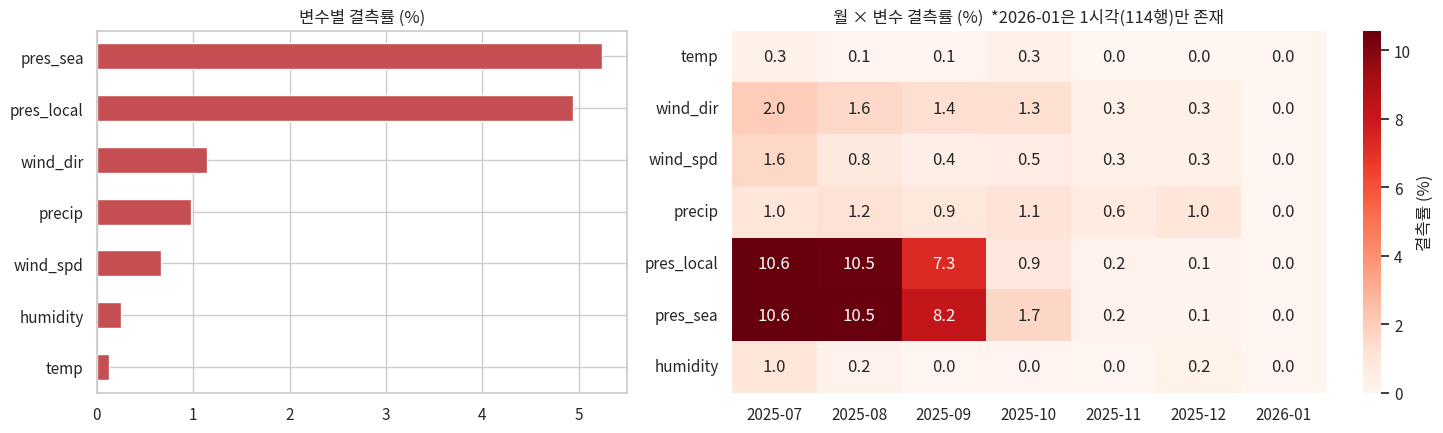

In [5]:
num_cols = ["temp", "wind_dir", "wind_spd", "precip", "pres_local", "pres_sea", "humidity"]

miss = pd.DataFrame({
    "결측 수": df[num_cols].isna().sum(),
    "결측률(%)": df[num_cols].isna().mean() * 100,
})
display(miss)

month = df["datetime"].dt.to_period("M").astype(str)
miss_m = df[num_cols].isna().groupby(month).mean().T * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
miss["결측률(%)"].sort_values().plot.barh(ax=axes[0], color="#C44E52")
axes[0].set_title("변수별 결측률 (%)")
sns.heatmap(miss_m, annot=True, fmt=".1f", cmap="Reds", ax=axes[1], cbar_kws={"label": "결측률 (%)"})
axes[1].set_title("월 × 변수 결측률 (%)  *2026-01은 1시각(114행)만 존재")
axes[1].set_xlabel("")
plt.tight_layout()

현지기압 결측률 30% 초과 지점: 12개 / 115개


,temp,wind_dir,wind_spd,precip,pres_local,pres_sea,humidity
station_name,,,,,,,
남산,0.046,1.369,1.369,0.570,58.065,60.963,0.068
등봉,0.023,0.045,0.068,0.634,57.913,58.026,0.091
광덕산,0.046,0.456,0.456,3.213,50.490,50.558,18.410
춘천신북,0.023,0.023,0.023,0.182,49.430,57.729,0.023
한강,0.045,0.045,0.045,0.522,47.029,47.506,0.023
도계,0.045,0.068,0.068,0.136,45.904,46.517,0.045
하장,0.023,0.068,0.068,0.340,45.360,46.517,0.023
옥계,0.023,0.023,0.023,0.114,42.411,45.123,0.023
하조대,0.023,0.023,0.023,0.364,41.338,43.364,0.023


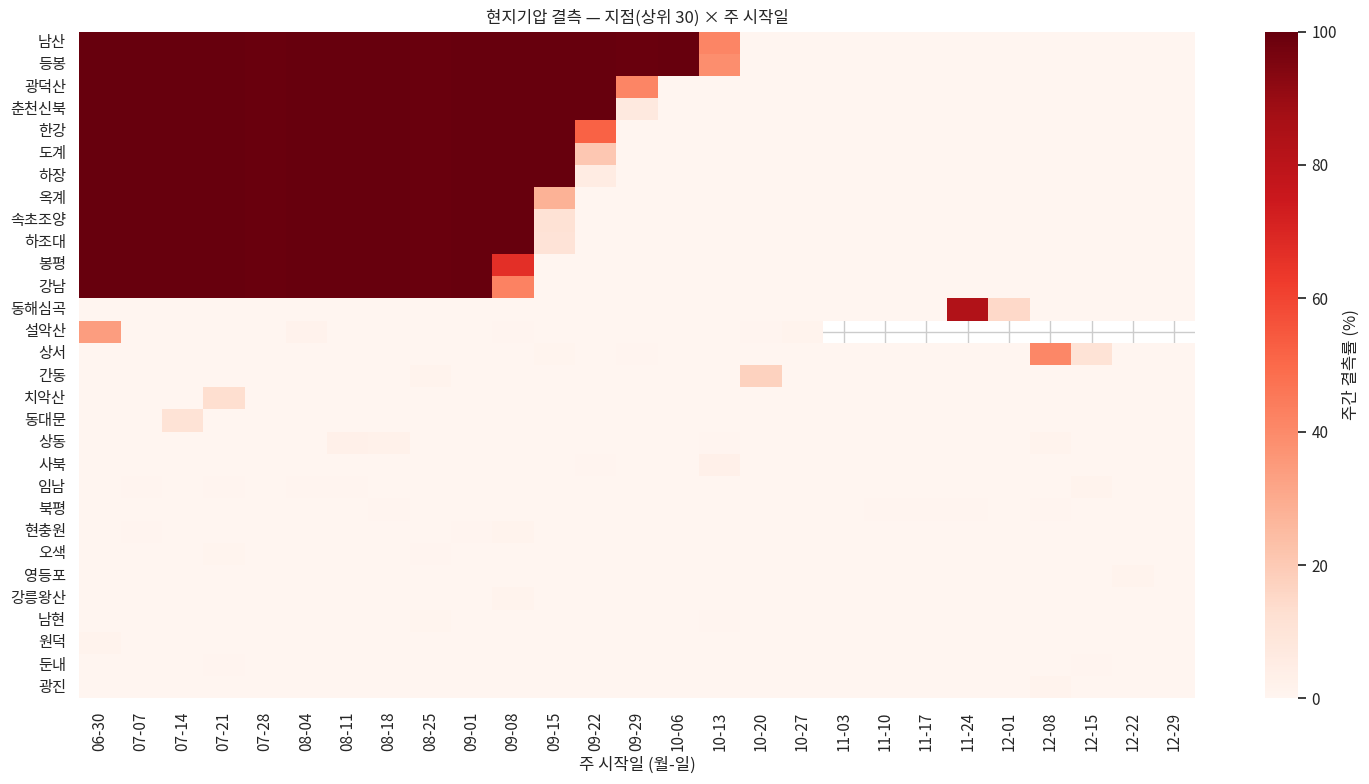

In [6]:
# 지점별 결측: 기압 결측이 특정 지점에 몰려 있는지
st_miss = df[num_cols].isna().groupby(df["station_name"]).mean() * 100
print(f"현지기압 결측률 30% 초과 지점: {(st_miss['pres_local'] > 30).sum()}개 / {len(st_miss)}개")
display(st_miss.sort_values("pres_local", ascending=False).head(10))

# 지점 × 주 단위 현지기압 결측률 (결측 상위 30개 지점) — 장비 장애 구간 확인
name_of = df.drop_duplicates("station_id").set_index("station_id")["station_name"]
wk = df["datetime"].dt.to_period("W").dt.start_time.dt.strftime("%m-%d")
pm = df["pres_local"].isna().groupby([df["station_id"], wk]).mean().unstack() * 100
top = pm.mean(axis=1).sort_values(ascending=False).head(30).index
pm_top = pm.loc[top]
pm_top.index = [name_of[i] for i in pm_top.index]

plt.figure(figsize=(15, 8))
sns.heatmap(pm_top, cmap="Reds", cbar_kws={"label": "주간 결측률 (%)"})
plt.title("현지기압 결측 — 지점(상위 30) × 주 시작일")
plt.xlabel("주 시작일 (월-일)")
plt.tight_layout()

### 2.2 센티널 값 (-99.x)

In [7]:
sent_mask = (df[num_cols] <= -90)
print("컬럼별 센티널(≤ -90) 건수")
display(sent_mask.sum().rename("건수").to_frame().T)

rows = df[sent_mask.any(axis=1)]
print(f"해당 행: {len(rows)}건, 지점 {rows['station_id'].nunique()}개")
print("\n[발생 시각 분포]  → 월말 00시에 집중되는지 확인")
display(rows["datetime"].dt.strftime("%Y-%m-%d %H:%M").value_counts().sort_index().rename("건수").to_frame())
display(rows[["station_name", "datetime", "pres_local", "pres_sea", "humidity"]].head(8))

컬럼별 센티널(≤ -90) 건수


,temp,wind_dir,wind_spd,precip,pres_local,pres_sea,humidity
건수,0,0,0,0,28,0,1


해당 행: 28건, 지점 13개

[발생 시각 분포]  → 월말 00시에 집중되는지 확인


,건수
datetime,
2025-07-31 00:00,12
2025-08-31 00:00,12
2025-09-30 00:00,3
2025-11-30 00:00,1


,station_name,datetime,pres_local,pres_sea,humidity
27157,등봉,2025-07-31,-99.700,NaN,100.000
27901,등봉,2025-08-31,-99.700,NaN,99.000
28621,등봉,2025-09-30,-99.700,NaN,100.000
34495,동해심곡,2025-11-30,-99.200,NaN,68.000
80053,하조대,2025-07-31,-99.700,NaN,98.000
80797,하조대,2025-08-31,-99.700,NaN,96.000
93280,강남,2025-07-31,-99.700,NaN,59.000
94024,강남,2025-08-31,-99.700,NaN,88.000


### 2.3 풍향 = 0 문제

,비율(%)
그룹,
풍향>0 (정상),80.311
풍향0 & 풍속>0 (풍향 미확정),14.193
풍향0 & 풍속0 (정온),5.497



[풍향 미확정 그룹의 풍속 분포]


,count,mean,std,min,50%,90%,99%,max
풍속(m/s),"70,886.000",0.255,0.116,0.100,0.300,0.400,0.400,3.400


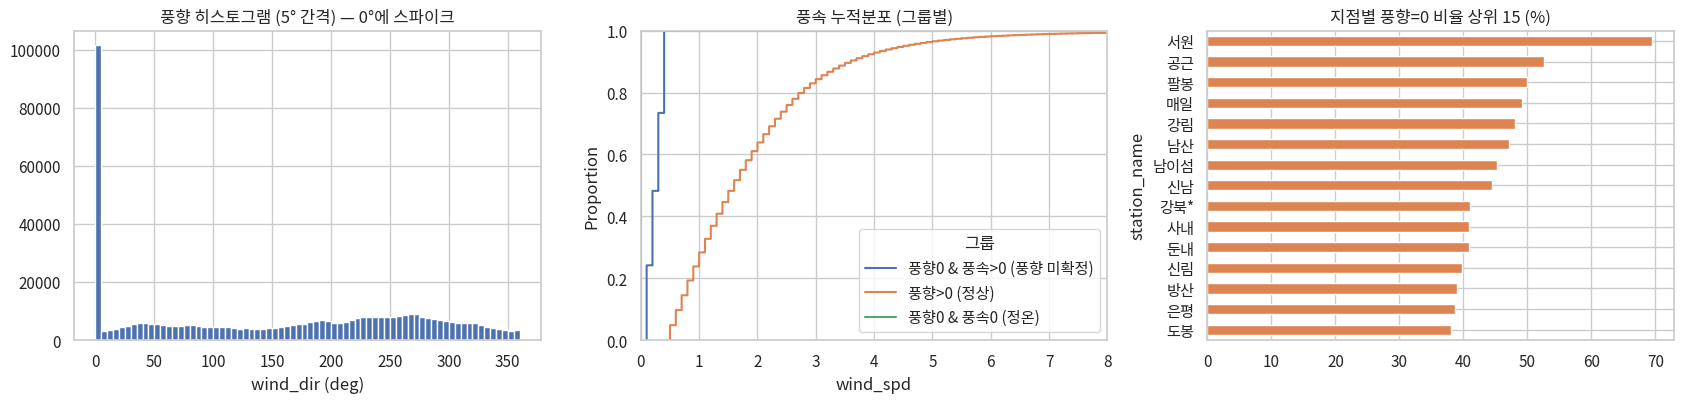

In [8]:
wd = df.dropna(subset=["wind_dir", "wind_spd"])
grp = np.select(
    [(wd["wind_dir"] == 0) & (wd["wind_spd"] == 0), (wd["wind_dir"] == 0) & (wd["wind_spd"] > 0)],
    ["풍향0 & 풍속0 (정온)", "풍향0 & 풍속>0 (풍향 미확정)"],
    default="풍향>0 (정상)",
)
grp = pd.Series(grp, index=wd.index, name="그룹")
display((grp.value_counts(normalize=True) * 100).rename("비율(%)").to_frame())

print("\n[풍향 미확정 그룹의 풍속 분포]")
display(wd.loc[grp == "풍향0 & 풍속>0 (풍향 미확정)", "wind_spd"].describe(percentiles=[.5, .9, .99]).to_frame("풍속(m/s)").T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(wd["wind_dir"], bins=72, color="#4C72B0")
axes[0].set_title("풍향 히스토그램 (5° 간격) — 0°에 스파이크")
axes[0].set_xlabel("wind_dir (deg)")

sns.ecdfplot(data=pd.DataFrame({"wind_spd": wd["wind_spd"], "그룹": grp}), x="wind_spd", hue="그룹", ax=axes[1])
axes[1].set_xlim(0, 8)
axes[1].set_title("풍속 누적분포 (그룹별)")

share0 = (df["wind_dir"] == 0).groupby(df["station_name"]).mean().sort_values(ascending=False) * 100
share0.head(15).sort_values().plot.barh(ax=axes[2], color="#DD8452")
axes[2].set_title("지점별 풍향=0 비율 상위 15 (%)")
plt.tight_layout()

### 2.4 시간축 연속성 & 물리적 일관성

In [9]:
full_idx = pd.date_range(df["datetime"].min(), df["datetime"].max(), freq="h")
n_exp = len(full_idx)

cnt = df.groupby("station_id").agg(station_name=("station_name", "first"), n=("datetime", "size"),
                                   start=("datetime", "min"), end=("datetime", "max"))
cnt["누락 시각 수"] = n_exp - cnt["n"]

print(f"기대 시각 수(지점당): {n_exp:,}  |  완전한 지점: {(cnt['누락 시각 수'] == 0).sum()}개  "
      f"|  누락 있는 지점: {(cnt['누락 시각 수'] > 0).sum()}개")
print(f"총 누락 시각 수: {int(cnt['누락 시각 수'].sum()):,} (= {cnt.shape[0]}×{n_exp:,} - {len(df):,})")
display(cnt[cnt["누락 시각 수"] > 0].sort_values("누락 시각 수", ascending=False).head(8))

기대 시각 수(지점당): 4,417  |  완전한 지점: 71개  |  누락 있는 지점: 44개
총 누락 시각 수: 2,679 (= 115×4,417 - 505,276)


,station_name,n,start,end,누락 시각 수
station_id,,,,,
875,설악산,2871,2025-07-01,2025-10-30 11:00:00,1546
581,상동,4265,2025-07-01,2026-01-01 00:00:00,152
425,남현,4325,2025-07-01,2026-01-01 00:00:00,92
596,오색,4332,2025-07-01,2026-01-01 00:00:00,85
338,둔내,4345,2025-07-01,2026-01-01 00:00:00,72
322,상서,4352,2025-07-01,2026-01-01 00:00:00,65
510,영등포,4370,2025-07-01,2026-01-01 00:00:00,47
519,사내,4379,2025-07-01,2026-01-01 00:00:00,38


In [10]:
checks = {
    "습도 범위 이탈 (0~100 밖)":      int(((df["humidity"] < 0) | (df["humidity"] > 100)).sum()),
    "풍향 범위 이탈 (0~360 밖)":      int(((df["wind_dir"] < 0) | (df["wind_dir"] > 360)).sum()),
    "풍속 < 0":                       int((df["wind_spd"] < 0).sum()),
    "강수량 < 0":                     int((df["precip"] < 0).sum()),
    "해면기압 < 현지기압 (비정상)":    int((df["pres_sea"] < df["pres_local"]).sum()),
    "현지기압 있음 & 해면기압 결측":   int((df["pres_local"].notna() & df["pres_sea"].isna()).sum()),
    "현지기압 결측 & 해면기압 있음":   int((df["pres_local"].isna() & df["pres_sea"].notna()).sum()),
}
display(pd.Series(checks, name="건수").to_frame())

,건수
습도 범위 이탈 (0~100 밖),1
풍향 범위 이탈 (0~360 밖),0
풍속 < 0,0
강수량 < 0,0
해면기압 < 현지기압 (비정상),0
현지기압 있음 & 해면기압 결측,1501
현지기압 결측 & 해면기압 있음,0


## 3. 기초 정제

점검 결과에 따라 아래 규칙으로 1차 정제합니다 (값을 *만들어내지* 않는 단계).

1. **센티널(≤ -90) → NaN**
2. **풍향 0 → NaN** 으로 바꾸되, "풍속>0인데 풍향 0"인 행은 `wind_dir_undet=1` 플래그로 보존 (기상청 표기에서 정온/미확정은 0, 북풍은 360)
3. **지점 × 전체 시간 격자 완성**: 누락된 관측 시각을 NaN 행으로 채워 이후 `shift`/`rolling`이 정확히 "N시간 전"을 가리키도록 함 (`is_inserted` 플래그)

In [11]:
clean = df.sort_values(["station_id", "datetime"]).reset_index(drop=True)

# 1) 센티널 → NaN
for c in num_cols:
    clean.loc[clean[c] <= -90, c] = np.nan

# 2) 풍향 0 처리
clean["wind_dir_undet"] = ((clean["wind_dir"] == 0) & (clean["wind_spd"] > 0)).astype(int)
clean.loc[clean["wind_dir"] == 0, "wind_dir"] = np.nan

# 3) 지점 × 시간 격자 완성
clean["is_inserted"] = 0
idx = pd.MultiIndex.from_product([sorted(clean["station_id"].unique()), full_idx], names=["station_id", "datetime"])
grid = clean.set_index(["station_id", "datetime"]).reindex(idx).reset_index()
grid["station_name"] = grid["station_id"].map(name_of)
grid["is_inserted"] = grid["is_inserted"].fillna(1).astype(int)
grid["wind_dir_undet"] = grid["wind_dir_undet"].fillna(0).astype(int)

print(f"행 수: {len(df):,} → {len(grid):,}  (삽입된 누락 시각 행 {grid['is_inserted'].sum():,}개)")
print(f"센티널 제거 후 현지기압 min = {grid['pres_local'].min():.1f}, 습도 min = {grid['humidity'].min():.1f}")
print(f"풍향 미확정(풍향0 & 풍속>0) 플래그: {grid['wind_dir_undet'].sum():,}행 ({grid['wind_dir_undet'].mean()*100:.1f}%)")
grid.head()

행 수: 505,276 → 507,955  (삽입된 누락 시각 행 2,679개)
센티널 제거 후 현지기압 min = 822.6, 습도 min = 8.0
풍향 미확정(풍향0 & 풍속>0) 플래그: 70,886행 (14.0%)


,station_id,datetime,station_name,temp,wind_dir,wind_spd,precip,pres_local,pres_sea,humidity,wind_dir_undet,is_inserted
0,310,2025-07-01 00:00:00,궁촌,24.800,NaN,0.200,0.000,"1,007.800","1,009.400",83.000,1,0
1,310,2025-07-01 01:00:00,궁촌,24.800,307.000,0.700,0.000,"1,007.800","1,009.400",82.000,0,0
2,310,2025-07-01 02:00:00,궁촌,24.400,258.300,0.900,0.000,"1,007.700","1,009.300",84.000,0,0
3,310,2025-07-01 03:00:00,궁촌,24.500,NaN,0.400,0.000,"1,008.200","1,009.800",83.000,1,0
4,310,2025-07-01 04:00:00,궁촌,24.000,204.200,0.800,0.000,"1,008.600","1,010.200",85.000,0,0


## 4. EDA — 시각화

보간·대체 **이전**의 정제 데이터로 분포와 패턴을 먼저 봅니다. (2026-01-01 00시 1개 시각은 일 단위 집계에서 제외)

In [12]:
eda = grid[grid["datetime"] < "2026-01-01"].copy()
eda["month"] = eda["datetime"].dt.month
eda["hour"] = eda["datetime"].dt.hour
eda["is_rain"] = np.where(eda["precip"].isna(), np.nan, (eda["precip"] > 0).astype(float))
day = eda["datetime"].dt.floor("D")

cont = ["temp", "humidity", "wind_spd", "precip", "pres_local", "pres_sea"]
display(eda[cont].describe(percentiles=[.01, .5, .99]).T)

,count,mean,std,min,1%,50%,99%,max
temp,"504,532.000",15.544,10.928,-22.600,-9.400,17.600,33.800,38.900
humidity,"503,895.000",76.268,20.337,8.000,23.000,81.000,100.000,100.000
wind_spd,"501,815.000",1.634,1.550,0.000,0.000,1.300,7.100,22.500
precip,"500,226.000",0.221,1.335,0.000,0.000,0.000,5.500,92.500
pres_local,"480,161.000",986.783,32.364,822.600,873.700,995.900,"1,026.300","1,034.800"
pres_sea,"478,688.000","1,016.226",8.139,990.000,998.300,"1,016.100","1,031.500","1,037.200"


### 4.1 변수 분포

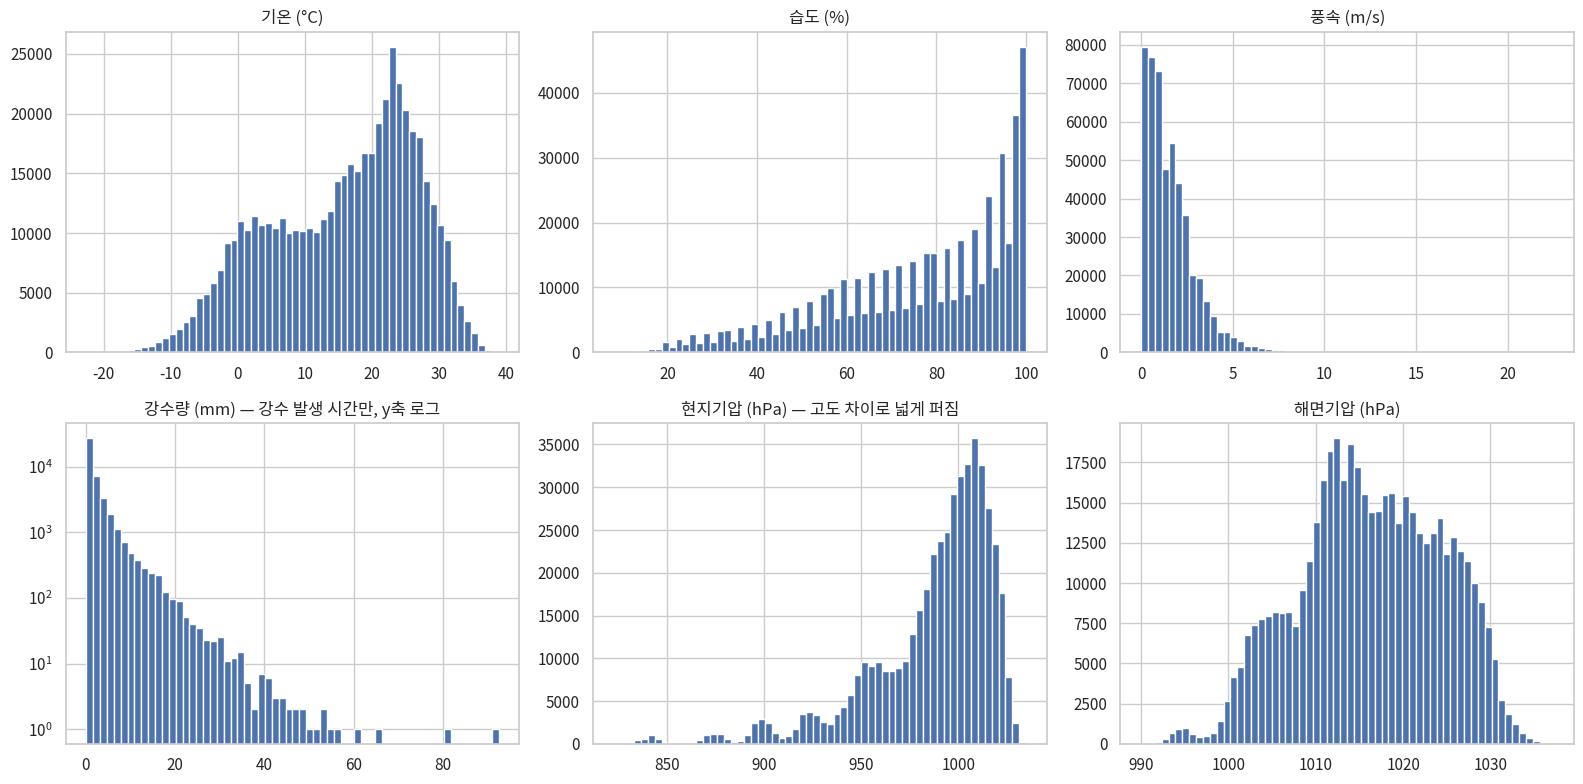

In [13]:
spec = [("temp", "기온 (°C)"), ("humidity", "습도 (%)"), ("wind_spd", "풍속 (m/s)"),
        ("precip", "강수량 (mm) — 강수 발생 시간만, y축 로그"),
        ("pres_local", "현지기압 (hPa) — 고도 차이로 넓게 퍼짐"), ("pres_sea", "해면기압 (hPa)")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (c, title) in zip(axes.ravel(), spec):
    s = eda[c].dropna()
    if c == "precip":
        s = s[s > 0]
        ax.set_yscale("log")
    ax.hist(s, bins=60, color="#4C72B0", edgecolor="white")
    ax.set_title(title)
plt.tight_layout()

### 4.2 일별 시계열 (전 지점)

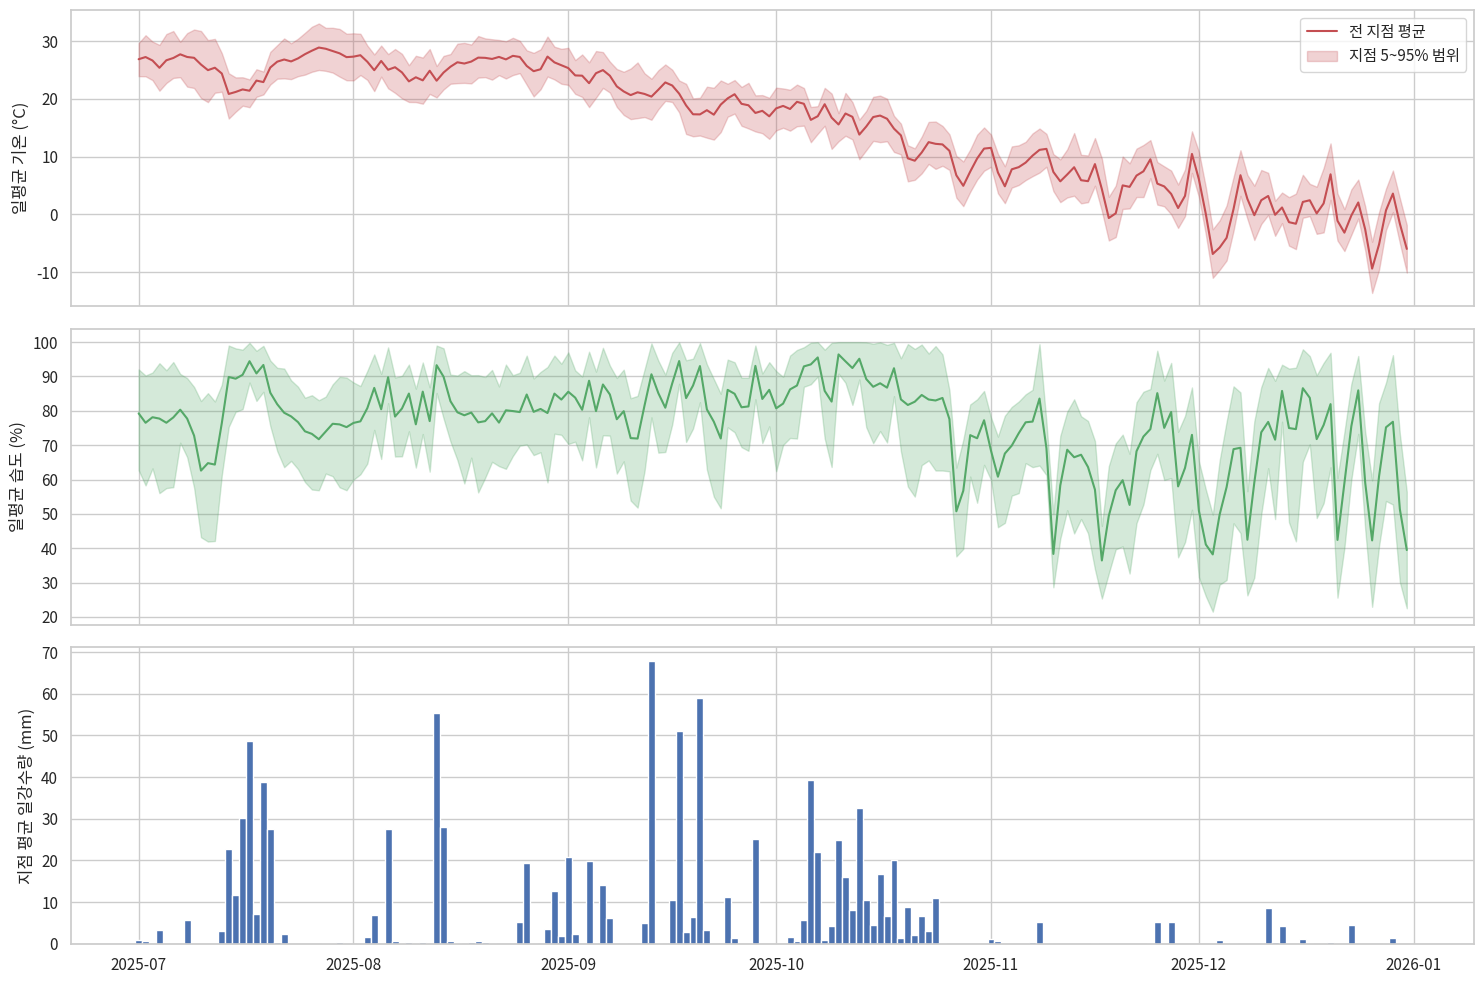

In [14]:
t_d = eda.groupby([day, "station_id"])["temp"].mean().unstack()
h_d = eda.groupby([day, "station_id"])["humidity"].mean().unstack()
p_d = eda.groupby([day, "station_id"])["precip"].sum(min_count=1).unstack()

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].plot(t_d.index, t_d.mean(axis=1), color="C3", label="전 지점 평균")
axes[0].fill_between(t_d.index, t_d.quantile(.05, axis=1), t_d.quantile(.95, axis=1), color="C3", alpha=.25, label="지점 5~95% 범위")
axes[0].set_ylabel("일평균 기온 (°C)"); axes[0].legend(loc="upper right")

axes[1].plot(h_d.index, h_d.mean(axis=1), color="C2")
axes[1].fill_between(h_d.index, h_d.quantile(.05, axis=1), h_d.quantile(.95, axis=1), color="C2", alpha=.25)
axes[1].set_ylabel("일평균 습도 (%)")

axes[2].bar(p_d.index, p_d.mean(axis=1), color="C0", width=1.0)
axes[2].set_ylabel("지점 평균 일강수량 (mm)")
plt.tight_layout()

In [15]:
monthly = pd.DataFrame({
    "평균기온(°C)": eda.groupby("month")["temp"].mean(),
    "평균습도(%)": eda.groupby("month")["humidity"].mean(),
    "평균풍속(m/s)": eda.groupby("month")["wind_spd"].mean(),
    "지점평균 월강수량(mm)": eda.groupby(["month", "station_id"])["precip"].sum(min_count=1).groupby("month").mean(),
    "강수 시간 비율(%)": eda.groupby("month")["is_rain"].mean() * 100,
})
display(monthly)

,평균기온(°C),평균습도(%),평균풍속(m/s),지점평균 월강수량(mm),강수 시간 비율(%)
month,,,,,
7,25.908,78.594,1.588,201.343,8.981
8,25.808,81.258,1.524,166.590,6.718
9,20.768,83.407,1.403,307.033,12.621
10,14.161,83.812,1.457,247.165,19.771
11,6.531,65.696,1.821,18.592,1.966
12,-0.175,64.600,2.013,22.517,2.850


### 4.3 일주기 (시간대 패턴, 월별)

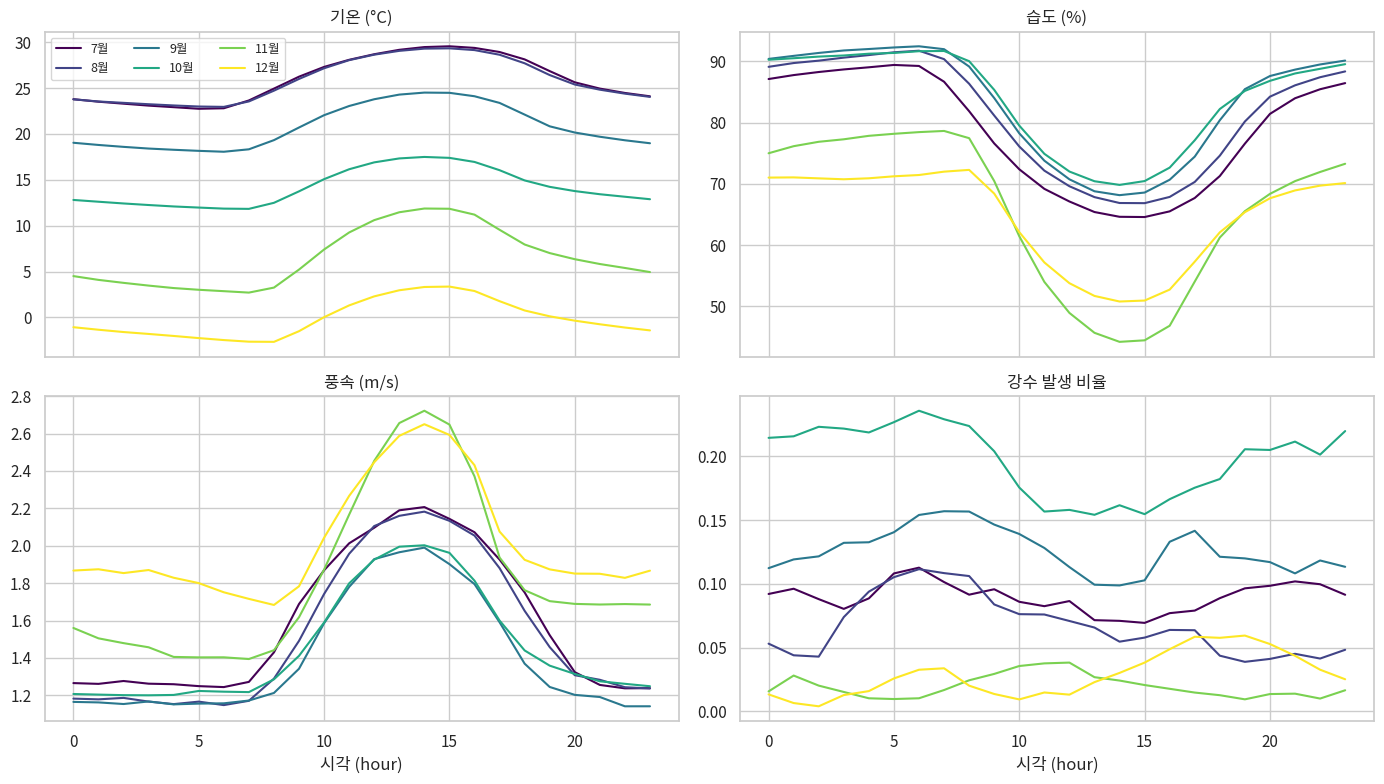

In [16]:
hourly = eda.groupby(["month", "hour"]).agg(temp=("temp", "mean"), humidity=("humidity", "mean"),
                                            wind_spd=("wind_spd", "mean"), rain=("is_rain", "mean"))
labels = {"temp": "기온 (°C)", "humidity": "습도 (%)", "wind_spd": "풍속 (m/s)", "rain": "강수 발생 비율"}
colors = plt.cm.viridis(np.linspace(0, 1, 6))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, col in zip(axes.ravel(), labels):
    for m, colr in zip(range(7, 13), colors):
        ax.plot(hourly.loc[m, col].index, hourly.loc[m, col].values, color=colr, label=f"{m}월")
    ax.set_title(labels[col])
axes[0, 0].legend(ncol=3, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("시각 (hour)")
plt.tight_layout()

### 4.4 강수

,시간 수,비율(%)
precip,,
무강수,455995,91.158
약함(<3),33239,6.645
보통(3~15),10108,2.021
강함(15~30),786,0.157
매우강함(≥30),98,0.020


,count,mean,std,min,50%,90%,99%,max
강수 발생 시간의 강수량(mm),"44,231.000",2.503,3.802,0.100,1.000,6.000,19.000,92.500


[전 지점 평균 일강수량 상위 5일]


,mm
datetime,
2025-09-13,67.754
2025-09-20,58.981
2025-08-13,55.449
2025-09-17,51.075
2025-07-17,48.660


[시간 강수량 상위 5건]


,station_name,datetime,precip
164473,은평,2025-08-13 12:00:00,92.500
111469,강서,2025-08-13 12:00:00,81.500
172450,한강,2025-07-08 19:00:00,65.500
115029,양천,2025-07-08 19:00:00,61.500
120303,도봉,2025-08-13 12:00:00,57.000


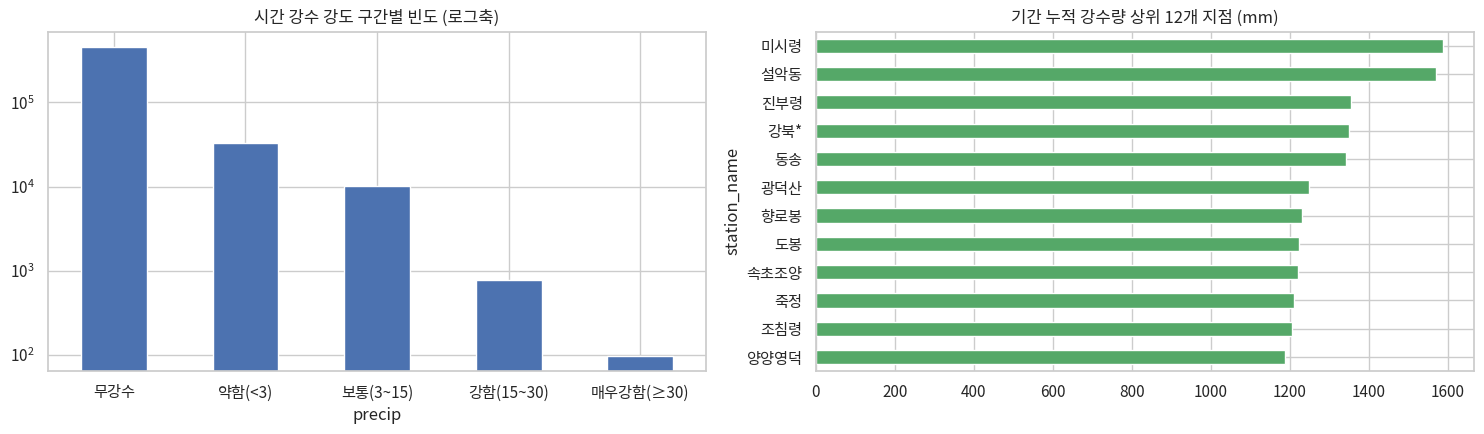

In [17]:
RAIN_LABELS = ["무강수", "약함(<3)", "보통(3~15)", "강함(15~30)", "매우강함(≥30)"]
cls = pd.cut(eda["precip"], [0, 0.1, 3, 15, 30, np.inf], right=False, labels=RAIN_LABELS)
cnt_cls = cls.value_counts().reindex(RAIN_LABELS)
display(pd.DataFrame({"시간 수": cnt_cls, "비율(%)": cnt_cls / cnt_cls.sum() * 100}))

rain_hours = eda.loc[eda["precip"] > 0, "precip"]
display(rain_hours.describe(percentiles=[.5, .9, .99]).to_frame("강수 발생 시간의 강수량(mm)").T)

print("[전 지점 평균 일강수량 상위 5일]")
display(p_d.mean(axis=1).sort_values(ascending=False).head(5).rename("mm").to_frame())
print("[시간 강수량 상위 5건]")
display(eda.nlargest(5, "precip")[["station_name", "datetime", "precip"]])

tot = eda.groupby("station_name")["precip"].sum(min_count=1).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
cnt_cls.plot.bar(ax=axes[0], color="#4C72B0", logy=True, rot=0)
axes[0].set_title("시간 강수 강도 구간별 빈도 (로그축)")
tot.head(12).sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("기간 누적 강수량 상위 12개 지점 (mm)")
plt.tight_layout()

### 4.5 바람장미 (계절 비교)

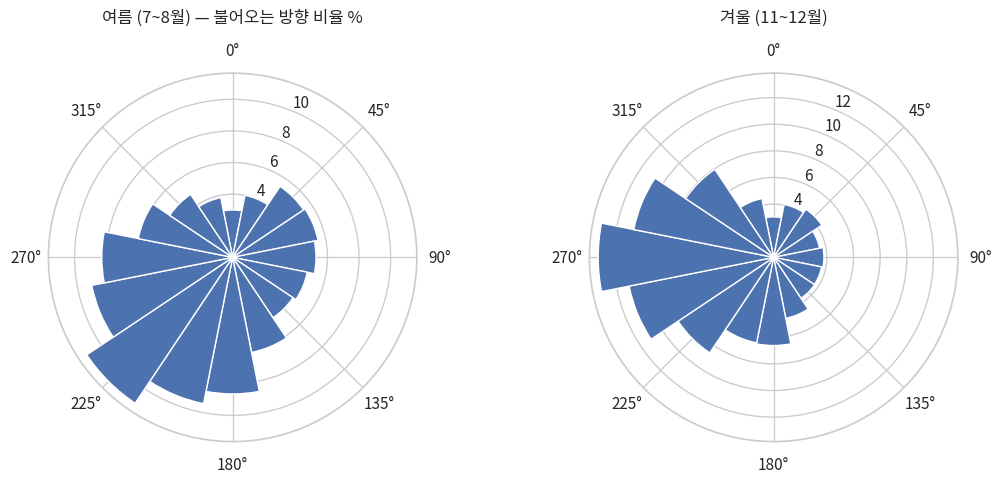

In [18]:
def wind_rose(ax, d, title, n=16):
    ang = d["wind_dir"].dropna() % 360
    shifted = (ang + 360 / n / 2) % 360                 # 북(N)이 섹터 중앙에 오도록 이동
    counts, _ = np.histogram(shifted, bins=np.linspace(0, 360, n + 1))
    theta = np.deg2rad(np.arange(n) * 360 / n)
    ax.bar(theta, counts / counts.sum() * 100, width=2 * np.pi / n, color="#4C72B0", edgecolor="white")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(title, pad=14)

fig, axes = plt.subplots(1, 2, figsize=(11, 5), subplot_kw={"projection": "polar"})
wind_rose(axes[0], eda[eda["month"].isin([7, 8])], "여름 (7~8월) — 불어오는 방향 비율 %")
wind_rose(axes[1], eda[eda["month"].isin([11, 12])], "겨울 (11~12월)")
plt.tight_layout()

### 4.6 상관관계

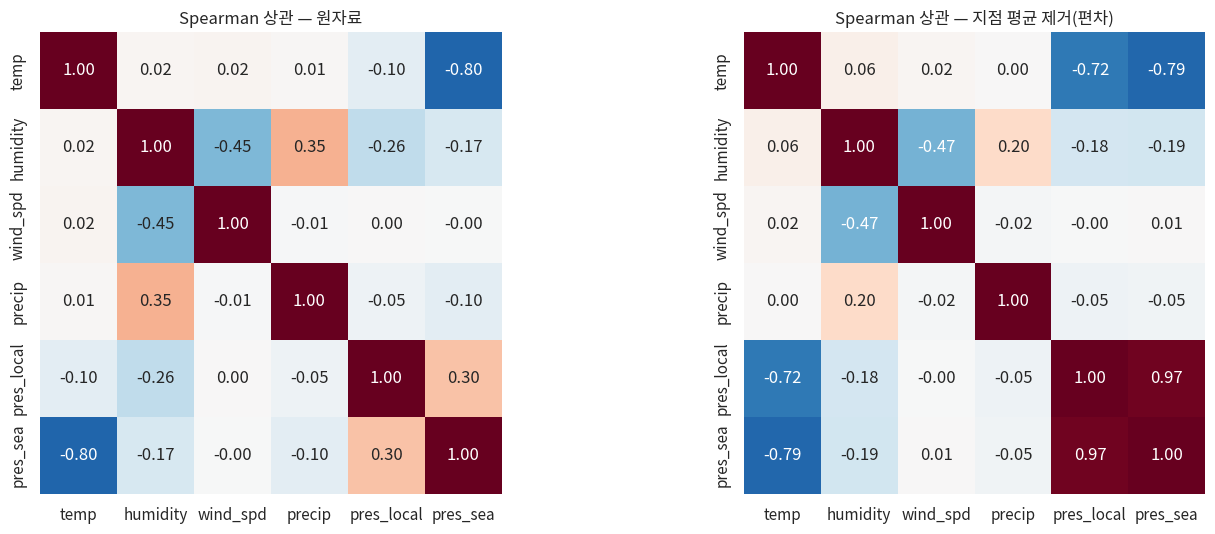

In [19]:
cols = ["temp", "humidity", "wind_spd", "precip", "pres_local", "pres_sea"]
anom = eda[cols] - eda.groupby("station_id")[cols].transform("mean")   # 지점 평균 제거(지점 고정효과 제거)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, data, title in zip(axes, [eda[cols], anom], ["Spearman 상관 — 원자료", "Spearman 상관 — 지점 평균 제거(편차)"]):
    sns.heatmap(data.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, ax=ax, cbar=False)
    ax.set_title(title)
plt.tight_layout()

### 4.7 지점 특성 — 고도 근사값과 기온

기온 관측률 95% 미만(회귀에서 제외): 설악산(64%)
고도 근사값 100 m 상승당 평균기온 -0.70 °C (상관계수 r = -0.90)


,station_name,temp_mean,elev_proxy_m,dtr_mean
station_id,,,,
320,향로봉,9.167,"1,182.720",5.169
682,임남,10.318,"1,001.280",6.034
695,광덕산,10.693,"1,039.920",6.357
418,한강,18.495,10.920,6.246
876,삼척,18.654,56.280,7.439
510,영등포,18.893,25.200,6.522


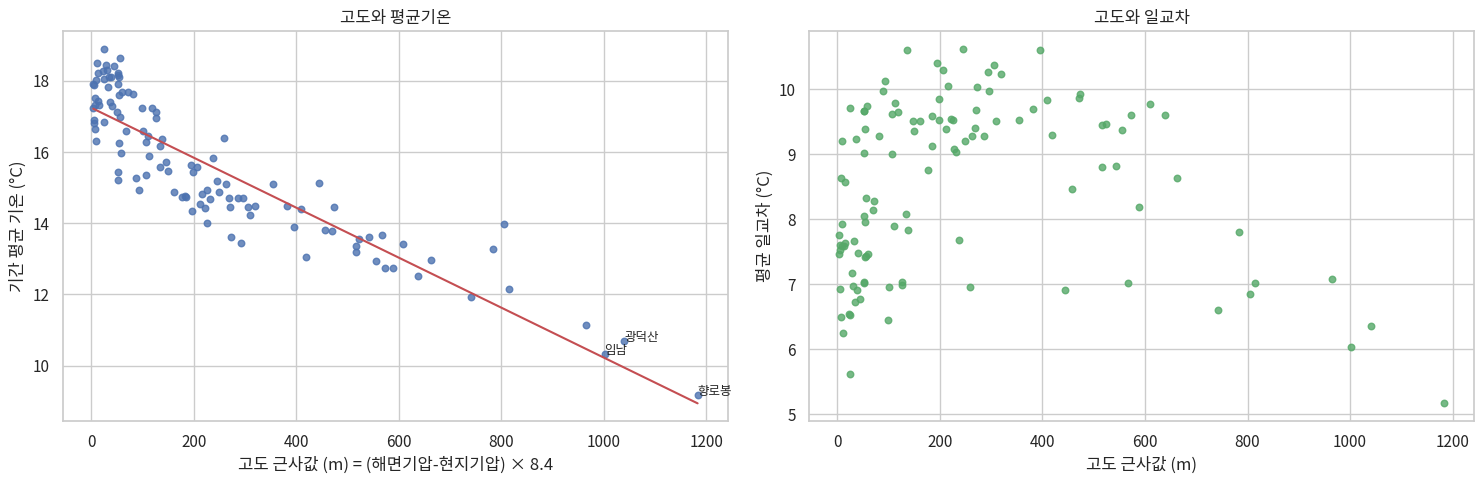

In [20]:
st = eda.groupby("station_id").agg(station_name=("station_name", "first"), temp_mean=("temp", "mean"),
                                   hum_mean=("humidity", "mean"), wspd_mean=("wind_spd", "mean"))
st["pres_offset_hpa"] = (eda["pres_sea"] - eda["pres_local"]).groupby(eda["station_id"]).median()
st["elev_proxy_m"] = st["pres_offset_hpa"] * 8.4          # 대략 1 hPa ≈ 8~9 m (근사)
dmax_min = eda.groupby([day, "station_id"])["temp"].agg(["max", "min"])
st["dtr_mean"] = (dmax_min["max"] - dmax_min["min"]).groupby("station_id").mean()

# 관측 기간이 짧은 지점은 평균이 계절 편향을 가짐 (예: 설악산은 10월 말까지만 관측 → 추운 11~12월 누락) → 제외하고 회귀
st["coverage"] = eda["temp"].notna().groupby(eda["station_id"]).mean()
low_cov = st[st["coverage"] < 0.95]
print("기온 관측률 95% 미만(회귀에서 제외):", ", ".join(f"{n}({c*100:.0f}%)" for n, c in zip(low_cov["station_name"], low_cov["coverage"])))
m = st[st["coverage"] >= 0.95].dropna(subset=["elev_proxy_m", "temp_mean"])
slope, icpt = np.polyfit(m["elev_proxy_m"], m["temp_mean"], 1)
r = m[["elev_proxy_m", "temp_mean"]].corr().iloc[0, 1]
print(f"고도 근사값 100 m 상승당 평균기온 {slope * 100:.2f} °C (상관계수 r = {r:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(m["elev_proxy_m"], m["temp_mean"], s=22, alpha=.8)
xs = np.linspace(m["elev_proxy_m"].min(), m["elev_proxy_m"].max(), 50)
axes[0].plot(xs, slope * xs + icpt, color="C3")
for _, row in pd.concat([m.nlargest(3, "elev_proxy_m"), m.nsmallest(2, "temp_mean")]).drop_duplicates().iterrows():
    axes[0].annotate(row["station_name"], (row["elev_proxy_m"], row["temp_mean"]), fontsize=9)
axes[0].set_xlabel("고도 근사값 (m) = (해면기압-현지기압) × 8.4"); axes[0].set_ylabel("기간 평균 기온 (°C)")
axes[0].set_title("고도와 평균기온")

axes[1].scatter(m["elev_proxy_m"], m["dtr_mean"], s=22, alpha=.8, color="C2")
axes[1].set_xlabel("고도 근사값 (m)"); axes[1].set_ylabel("평균 일교차 (°C)")
axes[1].set_title("고도와 일교차")
plt.tight_layout()

srt = m.sort_values("temp_mean")
display(pd.concat([srt.head(3), srt.tail(3)])[["station_name", "temp_mean", "elev_proxy_m", "dtr_mean"]])

## 5. 결측치 · 이상치 처리

| 변수 | 처리 방침 | 이유 |
|---|---|---|
| 기온·습도·풍속·기압 | 지점별 선형 보간, **연속 3시간 이하 결측만** | 짧은 공백은 시간적으로 매끄러움 |
| 현지/해면기압 (장기 결측) | ① 지점 고정 오프셋(해면−현지)으로 상호 복원 ② 같은 시각 **전 지점 해면기압 중앙값 + 지점 편향**으로 추정 | 해면기압은 공간적으로 매우 매끄러움 → 검증 오차로 신뢰도 확인 |
| 강수량 | **대체하지 않음** (NaN 유지) | 0으로 채우면 강수를 과소추정, 보간은 비현실적 |
| 풍향 | 대체하지 않음 | 원형 변수. 풍속과 결합한 u/v 성분으로 사용 |
| 이상치 | 범위 규칙 + 급변 + 고정값 점검 후 **플래그 부여**. 앞뒤와 동떨어진 *단일 시점 기온 스파이크*만 NaN→재보간 | 극값(호우·강풍·급냉)은 실제 현상일 수 있어 삭제하지 않음 |

In [21]:
fill_cols = ["temp", "humidity", "wind_spd", "precip", "pres_local", "pres_sea"]
na_before = grid[fill_cols].isna().sum().rename("처리 전")

def interp_short_gaps(s, limit=3):
    """연속 결측이 limit 이하인 구간만 선형 보간 (긴 공백은 부분 채움 없이 그대로 NaN 유지)"""
    filled = s.interpolate(method="linear", limit_area="inside")
    isna = s.isna()
    run_len = isna.groupby((~isna).cumsum()).transform("sum")
    return filled.where(~(isna & (run_len > limit)), np.nan)

for c in ["temp", "humidity", "wind_spd", "pres_local", "pres_sea"]:
    grid[c] = grid.groupby("station_id")[c].transform(interp_short_gaps)

na_short = grid[fill_cols].isna().sum().rename("단기 보간 후")
display(pd.concat([na_before, na_short], axis=1))

,처리 전,단기 보간 후
temp,3309,3209
humidity,3946,3859
wind_spd,6026,5193
precip,7615,7615
pres_local,27680,27616
pres_sea,29153,29075


### 5.1 기압 복원 — 지점 오프셋 + 지점 간 추정

In [22]:
# (a) 지점 고정 오프셋: 해면기압 - 현지기압 (관측소 고도에 의해 거의 상수)
diff = grid["pres_sea"] - grid["pres_local"]
offset = diff.groupby(grid["station_id"]).median()
print("오프셋 지점 분포(hPa):"); display(offset.describe().to_frame("offset").T)
print(f"지점 내 오프셋 변동(표준편차) 중앙값: {diff.groupby(grid['station_id']).std().median():.2f} hPa")

# (b) 지점 간 추정 검증 — leave-one-out: 자기 지점을 뺀 나머지 지점의 중앙값 + 지점 편향
pv = grid.pivot(index="datetime", columns="station_id", values="pres_sea")
errs = []
for sid in pv.columns:
    net_loo = pv.drop(columns=sid).median(axis=1)
    bias = (pv[sid] - net_loo).median()
    errs.append((pv[sid] - (net_loo + bias)).dropna())
err = pd.concat(errs)
print(f"\n[해면기압 지점 간 추정 오차, leave-one-out]  MAE={err.abs().mean():.2f}  RMSE={np.sqrt((err**2).mean()):.2f}  "
      f"P95(|e|)={err.abs().quantile(.95):.2f} hPa")

오프셋 지점 분포(hPa):


,count,mean,std,min,25%,50%,75%,max
offset,115.000,29.921,33.219,0.500,6.200,17.800,40.150,170.200


지점 내 오프셋 변동(표준편차) 중앙값: 0.97 hPa

[해면기압 지점 간 추정 오차, leave-one-out]  MAE=0.81  RMSE=1.09  P95(|e|)=2.30 hPa


In [23]:
# 실제 복원 수행
n_pres_missing_before = grid[["pres_local", "pres_sea"]].isna().any(axis=1).sum()
had_na = grid[["pres_local", "pres_sea"]].isna().any(axis=1)
off_row = grid["station_id"].map(offset)

# 1) 현지기압은 있는데 해면기압이 없는 경우 → 현지 + 오프셋
grid["pres_sea"] = grid["pres_sea"].fillna(grid["pres_local"] + off_row)

# 2) 둘 다 없는 경우 → 같은 시각 전 지점 해면기압 중앙값 + 지점 편향
net = pv.median(axis=1)
bias = pv.sub(net, axis=0).median()
est = pv.copy()
est[:] = net.values[:, None] + bias.values[None, :]
est_long = est.stack().rename("pres_sea_est").reset_index()
grid = grid.merge(est_long, on=["datetime", "station_id"], how="left")
grid["pres_sea"] = grid["pres_sea"].fillna(grid["pres_sea_est"])
grid = grid.drop(columns="pres_sea_est")

# 3) 해면기압 기반으로 현지기압 복원
grid["pres_local"] = grid["pres_local"].fillna(grid["pres_sea"] - off_row)

grid["pres_imputed"] = (had_na & grid[["pres_local", "pres_sea"]].notna().all(axis=1)).astype(int)
print(f"기압 결측(둘 중 하나라도) 행: {n_pres_missing_before:,}  →  복원 {grid['pres_imputed'].sum():,}행, "
      f"남은 결측 {grid[['pres_local','pres_sea']].isna().any(axis=1).sum():,}행")

기압 결측(둘 중 하나라도) 행: 29,075  →  복원 29,075행, 남은 결측 0행


### 5.2 이상치 점검 (플래그만 부여)

In [24]:
rules = {"temp": (-40, 50), "humidity": (0, 100), "wind_spd": (0, 60), "precip": (0, 150),
         "pres_local": (500, 1100), "pres_sea": (900, 1100)}
rows = []
for c, (lo, hi) in rules.items():
    s = grid[c]
    rows.append({"변수": c, "허용 범위": f"{lo} ~ {hi}", "위반 건수": int(((s < lo) | (s > hi)).sum()),
                 "관측 최소": s.min(), "관측 최대": s.max()})
display(pd.DataFrame(rows).set_index("변수"))

# 단일 시점 스파이크: 앞뒤 값은 비슷한데(차이 3°C 이하) 해당 시점만 이웃 평균에서 10°C 넘게 벗어남 → 센서 오류로 보고 NaN 후 재보간
gp = grid.groupby("station_id")["temp"]
prev_t, next_t = gp.shift(1), gp.shift(-1)
spike = ((grid["temp"] - (prev_t + next_t) / 2).abs() > 10) & ((prev_t - next_t).abs() <= 3)
grid["flag_temp_spike"] = spike.astype(int)
print(f"단일 시점 기온 스파이크: {int(spike.sum())}건")
display(grid.loc[spike, ["station_name", "datetime", "temp"]].assign(prev=prev_t[spike], next=next_t[spike]))
grid.loc[spike, "temp"] = np.nan
grid["temp"] = grid.groupby("station_id")["temp"].transform(interp_short_gaps)

# 기온 급변: 1시간 사이 5°C 초과 (스파이크 제거 후에도 남는 것은 실제 현상일 가능성 — 호우 시 급냉 등)
dT = grid.groupby("station_id")["temp"].diff()
grid["flag_temp_jump"] = (dT.abs() > 5).astype(int)
print(f"기온 시간당 |Δ|>5°C: {grid['flag_temp_jump'].sum()}건 (지점 {grid.loc[grid['flag_temp_jump']==1, 'station_id'].nunique()}개)")
display(grid.loc[grid["flag_temp_jump"] == 1, ["station_name", "datetime", "temp"]]
        .assign(dT=dT[grid["flag_temp_jump"] == 1]).sort_values("dT", key=lambda s: s.abs(), ascending=False).head(8))

# 고정값(센서 정지 의심): 기온이 8시간 이상 완전히 같은 값
chg = grid.groupby("station_id")["temp"].diff().ne(0)
run_id = chg.groupby(grid["station_id"]).cumsum()
run_len = grid.groupby([grid["station_id"], run_id])["temp"].transform("size")
grid["flag_temp_stuck"] = ((run_len >= 8) & grid["temp"].notna()).astype(int)
print(f"\n기온 8시간 이상 동일값 행: {grid['flag_temp_stuck'].sum()}건 (지점 {grid.loc[grid['flag_temp_stuck']==1, 'station_id'].nunique()}개)")

,허용 범위,위반 건수,관측 최소,관측 최대
변수,,,,
temp,-40 ~ 50,0,-22.600,38.900
humidity,0 ~ 100,0,8.000,100.000
wind_spd,0 ~ 60,0,0.000,22.500
precip,0 ~ 150,0,0.000,92.500
pres_local,500 ~ 1100,0,822.600,"1,034.800"
pres_sea,900 ~ 1100,0,990.000,"1,037.200"


단일 시점 기온 스파이크: 1건


,station_name,datetime,temp,prev,next
405203,양지,2025-11-13 16:00:00,-10.000,15.200,12.600


기온 시간당 |Δ|>5°C: 932건 (지점 101개)


,station_name,datetime,temp,dT
141531,마포,2025-07-08 19:00:00,24.000,-10.700
185700,구로,2025-07-08 18:00:00,27.900,-10.300
110612,강서,2025-07-08 19:00:00,26.800,-9.800
159199,용산,2025-07-08 19:00:00,26.000,-9.800
145948,서대문,2025-07-08 19:00:00,24.300,-9.200
330611,연곡,2025-12-04 09:00:00,0.800,9.100
91638,조침령,2025-11-15 10:00:00,5.600,9.100
330270,연곡,2025-11-20 04:00:00,8.200,9.100



기온 8시간 이상 동일값 행: 80건 (지점 9개)


In [25]:
na_after = grid[fill_cols].isna().sum().rename("최종")
summary = pd.concat([na_before, na_short, na_after], axis=1)
summary["최종 결측률(%)"] = summary["최종"] / len(grid) * 100
display(summary)

,처리 전,단기 보간 후,최종,최종 결측률(%)
temp,3309,3209,3209,0.632
humidity,3946,3859,3859,0.760
wind_spd,6026,5193,5193,1.022
precip,7615,7615,7615,1.499
pres_local,27680,27616,0,0.000
pres_sea,29153,29075,0,0.000


## 6. 특징 엔지니어링

모든 시차·이동창 특징은 **지점별(`groupby station_id`)** 로, **과거 방향**으로만 계산합니다. 격자를 완성해 두었으므로 `shift(24)`는 정확히 24시간 전입니다.

### 6.1 시간 특징

In [26]:
fe = grid.copy()
dt = fe["datetime"].dt
fe["hour"] = dt.hour
fe["month"] = dt.month
fe["dayofweek"] = dt.dayofweek
fe["dayofyear"] = dt.dayofyear
fe["is_weekend"] = (fe["dayofweek"] >= 5).astype(int)
fe["hour_sin"] = np.sin(2 * np.pi * fe["hour"] / 24)
fe["hour_cos"] = np.cos(2 * np.pi * fe["hour"] / 24)
fe["doy_sin"] = np.sin(2 * np.pi * fe["dayofyear"] / 365.25)
fe["doy_cos"] = np.cos(2 * np.pi * fe["dayofyear"] / 365.25)
fe["daypart"] = pd.cut(fe["hour"], [-1, 5, 11, 17, 23], labels=["새벽", "오전", "오후", "저녁"])
fe[["datetime", "hour", "hour_sin", "hour_cos", "doy_sin", "doy_cos", "daypart"]].head(3)

,datetime,hour,hour_sin,hour_cos,doy_sin,doy_cos,daypart
0,2025-07-01 00:00:00,0,0.000,1.000,0.011,-1.000,새벽
1,2025-07-01 01:00:00,1,0.259,0.966,0.011,-1.000,새벽
2,2025-07-01 02:00:00,2,0.500,0.866,0.011,-1.000,새벽


### 6.2 물리 파생 특징 (이슬점·불쾌지수·체감온도)

In [27]:
# 이슬점 (Magnus 공식)
a, b = 17.62, 243.12
gamma = np.log(fe["humidity"].clip(lower=1) / 100) + a * fe["temp"] / (b + fe["temp"])
fe["dew_point"] = b * gamma / (a - gamma)
fe["dewpoint_depression"] = fe["temp"] - fe["dew_point"]          # 0에 가까울수록 포화(안개·강수 가능성)

# 불쾌지수 = 1.8T - 0.55(1-RH)(1.8T-26) + 32
fe["discomfort_index"] = 1.8 * fe["temp"] - 0.55 * (1 - fe["humidity"] / 100) * (1.8 * fe["temp"] - 26) + 32

# 체감온도(윈드칠): T ≤ 10°C & 풍속 ≥ 4.8 km/h 일 때만 적용
v = fe["wind_spd"] * 3.6
windchill = 13.12 + 0.6215 * fe["temp"] - 11.37 * v ** 0.16 + 0.3965 * v ** 0.16 * fe["temp"]
fe["feels_like"] = np.where((fe["temp"] <= 10) & (v >= 4.8), windchill, fe["temp"])
fe[["temp", "humidity", "dew_point", "dewpoint_depression", "discomfort_index", "feels_like"]].describe().T

,count,mean,std,min,25%,50%,75%,max
temp,"504,746.000",15.539,10.934,-22.600,6.800,17.600,24.200,38.900
humidity,"504,096.000",76.262,20.340,8.000,63.000,81.000,94.000,100.000
dew_point,"503,746.000",10.798,12.123,-30.748,0.980,15.285,21.112,28.478
dewpoint_depression,"503,746.000",4.737,4.722,-0.000,0.992,3.248,7.216,31.684
discomfort_index,"503,746.000",59.968,16.541,-2.445,47.034,63.232,74.081,88.906
feels_like,"504,746.000",15.088,11.627,-34.829,5.899,17.600,24.200,38.900


### 6.3 바람 특징 (u/v 성분)

In [28]:
# 풍향 미확정 행의 풍속 규모 확인 → 성분을 0으로 두어도 되는지 판단
undet_spd = fe.loc[fe["wind_dir_undet"] == 1, "wind_spd"]
print(f"풍향 미확정 행 풍속: 중앙값 {undet_spd.median():.2f}, P90 {undet_spd.quantile(.9):.2f}, "
      f"P99 {undet_spd.quantile(.99):.2f} m/s, 2 m/s 이상 비율 {(undet_spd >= 2).mean()*100:.1f}%")

rad = np.deg2rad(fe["wind_dir"])
calm = fe["wind_spd"].eq(0)
fe["wind_u"] = np.where(calm, 0.0, -fe["wind_spd"] * np.sin(rad))     # 동서 성분 (+: 동쪽으로 부는 바람)
fe["wind_v"] = np.where(calm, 0.0, -fe["wind_spd"] * np.cos(rad))     # 남북 성분 (+: 북쪽으로 부는 바람)
fe["wind_calm"] = np.where(fe["wind_spd"].isna(), np.nan, calm.astype(float))

# 풍향 미확정 = 풍속이 작아 풍향이 정해지지 않은 경우 → 성분 0 + 플래그(wind_dir_undet)로 정보 보존
fe.loc[fe["wind_dir_undet"] == 1, ["wind_u", "wind_v"]] = 0.0

def roll(col, win, fn, minp):
    return fe.groupby("station_id", sort=False)[col].rolling(win, min_periods=minp).agg(fn).reset_index(level=0, drop=True)

fe["wind_spd_mean3h"] = roll("wind_spd", 3, "mean", 2)
fe["wind_spd_max3h"] = roll("wind_spd", 3, "max", 2)
print(f"\nwind_u/v 결측률: {fe['wind_u'].isna().mean()*100:.2f}%  (풍향 자체가 측정 결측인 행)")

풍향 미확정 행 풍속: 중앙값 0.30, P90 0.40, P99 0.40 m/s, 2 m/s 이상 비율 0.0%

wind_u/v 결측률: 1.62%  (풍향 자체가 측정 결측인 행)


### 6.4 기압·기온·습도 변화량 및 이동창

In [29]:
g = fe.groupby("station_id", sort=False)
fe["pres_sea_chg_3h"] = fe["pres_sea"] - g["pres_sea"].shift(3)       # 기압 경향 (하강 → 저기압/강수 접근)
fe["pres_sea_chg_24h"] = fe["pres_sea"] - g["pres_sea"].shift(24)
fe["temp_diff_1h"] = fe["temp"] - g["temp"].shift(1)
fe["temp_diff_3h"] = fe["temp"] - g["temp"].shift(3)
fe["hum_diff_3h"] = fe["humidity"] - g["humidity"].shift(3)
fe["temp_lag_24h"] = g["temp"].shift(24)                              # 전일 같은 시각 기온

fe["temp_roll24_mean"] = roll("temp", 24, "mean", 18)
fe["temp_roll24_std"] = roll("temp", 24, "std", 18)
fe["temp_roll24_range"] = roll("temp", 24, "max", 18) - roll("temp", 24, "min", 18)   # 최근 24시간 기온 범위
fe[["pres_sea_chg_3h", "temp_diff_1h", "temp_lag_24h", "temp_roll24_mean", "temp_roll24_range"]].describe().T

,count,mean,std,min,25%,50%,75%,max
pres_sea_chg_3h,"507,610.000",0.012,1.281,-8.000,-0.800,0.100,0.800,7.100
temp_diff_1h,"504,564.000",-0.008,1.107,-10.700,-0.600,-0.100,0.400,9.100
temp_lag_24h,"502,010.000",15.657,10.842,-22.600,7.000,17.700,24.200,38.900
temp_roll24_mean,"502,278.000",15.583,10.455,-18.721,6.812,18.025,24.700,33.550
temp_roll24_range,"502,278.000",8.585,3.583,0.600,6.000,8.300,10.900,21.400


### 6.5 강수 특징

In [30]:
fe["is_rain"] = np.where(fe["precip"].isna(), np.nan, (fe["precip"] > 0).astype(float))
fe["rain_class"] = pd.cut(fe["precip"], [0, 0.1, 3, 15, 30, np.inf], right=False, labels=RAIN_LABELS)

# 누적 강수 (현재 시각 포함, 결측이 많은 창은 NaN 유지)
fe["precip_3h"] = roll("precip", 3, "sum", 3)
fe["precip_6h"] = roll("precip", 6, "sum", 5)
fe["precip_24h"] = roll("precip", 24, "sum", 18)

# 마지막 강수 이후 경과 시간 (지점별)
last_rain = fe["datetime"].where(fe["is_rain"] == 1)
last_rain = last_rain.groupby(fe["station_id"]).ffill()
fe["hours_since_rain"] = (fe["datetime"] - last_rain).dt.total_seconds() / 3600

fe[["precip", "is_rain", "precip_3h", "precip_6h", "precip_24h", "hours_since_rain"]].describe().T

,count,mean,std,min,25%,50%,75%,max
precip,"500,340.000",0.221,1.335,0.000,0.000,0.000,0.000,92.500
is_rain,"500,340.000",0.088,0.284,0.000,0.000,0.000,0.000,1.000
precip_3h,"499,351.000",0.665,3.276,0.000,0.000,0.000,0.000,134.500
precip_6h,"498,846.000",1.330,5.617,0.000,0.000,0.000,0.000,160.000
precip_24h,"495,337.000",5.323,14.892,0.000,0.000,0.000,1.500,247.500
hours_since_rain,"491,202.000",91.313,115.515,0.000,13.000,50.000,127.000,"1,626.000"


### 6.6 지점 특성

In [31]:
fe["elev_proxy_m"] = fe["station_id"].map(st["elev_proxy_m"])     # 지점 고정 고도 근사값
fe["station_id"] = fe["station_id"].astype("category")
new_cols = [c for c in fe.columns if c not in grid.columns]
print(f"신규 특징 {len(new_cols)}개:\n", new_cols)
print(f"\n최종 shape: {fe.shape}")

신규 특징 35개:
 ['hour', 'month', 'dayofweek', 'dayofyear', 'is_weekend', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'daypart', 'dew_point', 'dewpoint_depression', 'discomfort_index', 'feels_like', 'wind_u', 'wind_v', 'wind_calm', 'wind_spd_mean3h', 'wind_spd_max3h', 'pres_sea_chg_3h', 'pres_sea_chg_24h', 'temp_diff_1h', 'temp_diff_3h', 'hum_diff_3h', 'temp_lag_24h', 'temp_roll24_mean', 'temp_roll24_std', 'temp_roll24_range', 'is_rain', 'rain_class', 'precip_3h', 'precip_6h', 'precip_24h', 'hours_since_rain', 'elev_proxy_m']

최종 shape: (507955, 51)


### 6.7 파생 특징이 정보를 담고 있는지 확인

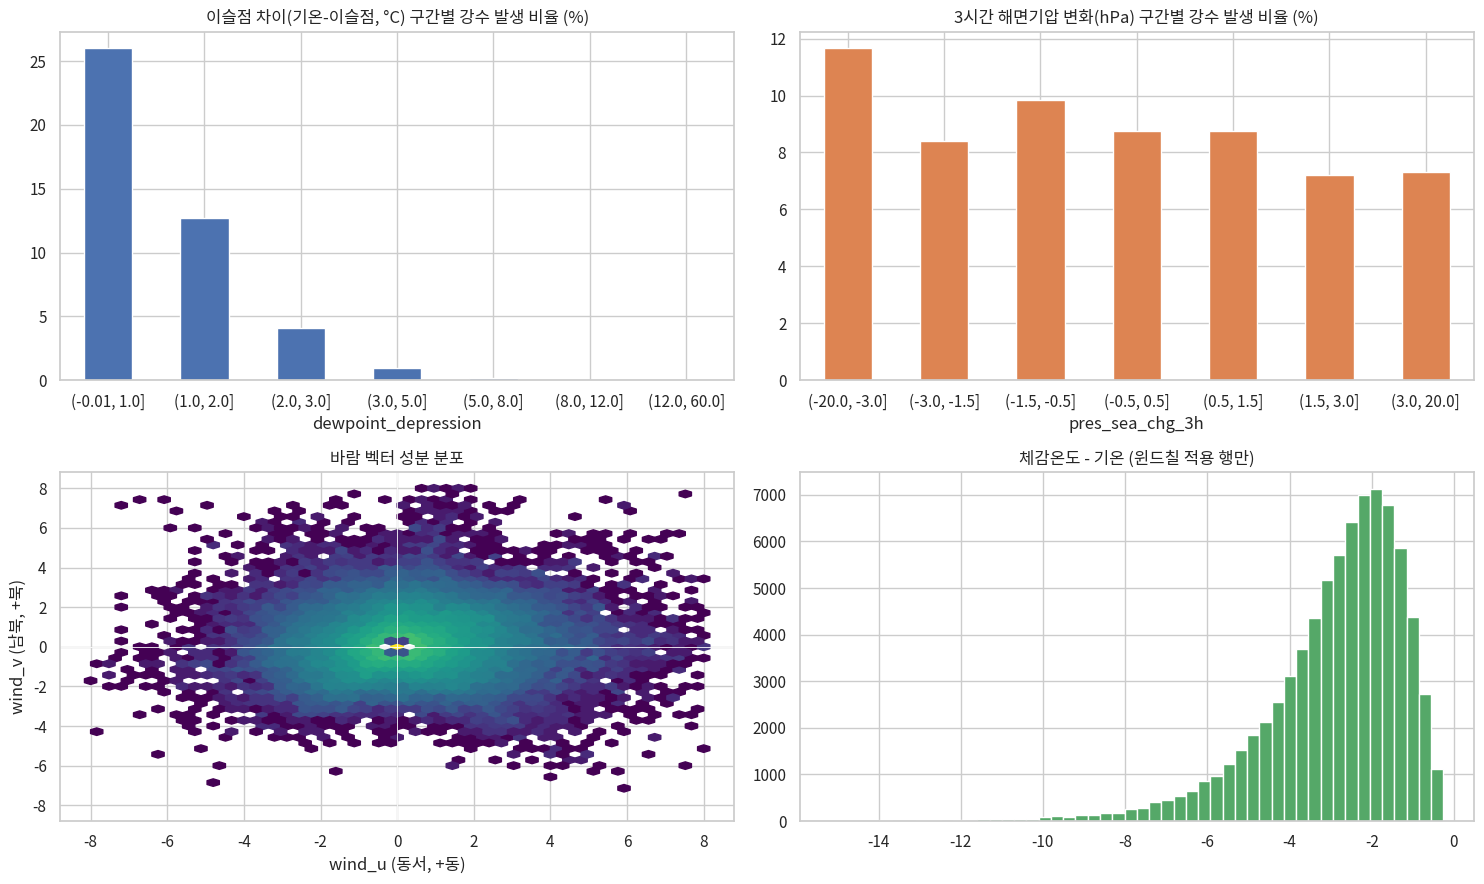

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# (a) 이슬점 차이 구간별 강수 발생 비율
b1 = pd.cut(fe["dewpoint_depression"], [-0.01, 1, 2, 3, 5, 8, 12, 60])
r1 = fe.groupby(b1, observed=True)["is_rain"].mean() * 100
r1.plot.bar(ax=axes[0, 0], color="#4C72B0", rot=0)
axes[0, 0].set_title("이슬점 차이(기온-이슬점, °C) 구간별 강수 발생 비율 (%)")

# (b) 3시간 해면기압 변화 구간별 강수 발생 비율
b2 = pd.cut(fe["pres_sea_chg_3h"], [-20, -3, -1.5, -0.5, 0.5, 1.5, 3, 20])
r2 = fe.groupby(b2, observed=True)["is_rain"].mean() * 100
r2.plot.bar(ax=axes[0, 1], color="#DD8452", rot=0)
axes[0, 1].set_title("3시간 해면기압 변화(hPa) 구간별 강수 발생 비율 (%)")

# (c) 풍속 성분 분포
samp = fe.dropna(subset=["wind_u", "wind_v"]).sample(60000, random_state=0)
axes[1, 0].hexbin(samp["wind_u"], samp["wind_v"], gridsize=50, bins="log", cmap="viridis", extent=(-8, 8, -8, 8))
axes[1, 0].axhline(0, color="w", lw=.6); axes[1, 0].axvline(0, color="w", lw=.6)
axes[1, 0].set_xlabel("wind_u (동서, +동)"); axes[1, 0].set_ylabel("wind_v (남북, +북)")
axes[1, 0].set_title("바람 벡터 성분 분포")

# (d) 체감온도 보정량
diff_fl = (fe["feels_like"] - fe["temp"])
axes[1, 1].hist(diff_fl[diff_fl < -0.01], bins=50, color="#55A868")
axes[1, 1].set_title("체감온도 - 기온 (윈드칠 적용 행만)")
plt.tight_layout()

## 7. 최종 점검 · 분할 예시 · 저장

In [33]:
final = fe.copy()
nan_rate = (final.isna().mean() * 100).sort_values(ascending=False)
print("결측률 상위 15개 컬럼 (%)")
display(nan_rate.head(15).to_frame("결측률(%)"))
print(f"shape: {final.shape}  |  메모리: {final.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

결측률 상위 15개 컬럼 (%)


,결측률(%)
wind_dir,21.028
hours_since_rain,3.298
precip_24h,2.484
precip_6h,1.793
precip_3h,1.694
wind_u,1.621
wind_v,1.621
rain_class,1.499
is_rain,1.499
precip,1.499


shape: (507955, 51)  |  메모리: 224 MB


In [34]:
# 시간 기반 분할 + 스케일링 예시 (임의 셔플 금지: 시계열 누수 방지)
from sklearn.preprocessing import StandardScaler

train = final[final["datetime"] < "2025-11-01"]
valid = final[(final["datetime"] >= "2025-11-01") & (final["datetime"] < "2025-12-01")]
test = final[final["datetime"] >= "2025-12-01"]
print(f"train {len(train):,} | valid {len(valid):,} | test {len(test):,}")

scale_cols = ["temp", "humidity", "wind_spd", "pres_sea", "dew_point", "discomfort_index", "feels_like",
              "pres_sea_chg_3h", "temp_roll24_mean", "elev_proxy_m"]
scaler = StandardScaler().fit(train[scale_cols])          # 스케일러는 train에만 fit
train_s = pd.DataFrame(scaler.transform(train[scale_cols]), columns=scale_cols)
display(train_s.describe().loc[["mean", "std"]].T)

train 339,480 | valid 82,800 | test 85,675


,mean,std
temp,0.000,1.000
humidity,-0.000,1.000
wind_spd,-0.000,1.000
pres_sea,0.000,1.000
dew_point,-0.000,1.000
discomfort_index,-0.000,1.000
feels_like,-0.000,1.000
pres_sea_chg_3h,-0.000,1.000
temp_roll24_mean,-0.000,1.000
elev_proxy_m,-0.000,1.000


In [35]:
OUT = "OBS_AWS_processed"
try:
    final.to_parquet(f"{OUT}.parquet", index=False)
    print(f"저장 완료: {OUT}.parquet")
except Exception as e:                                     # pyarrow 미설치 등
    final.to_csv(f"{OUT}.csv.gz", index=False, encoding="utf-8-sig", compression="gzip")
    print(f"parquet 저장 불가({type(e).__name__}) → {OUT}.csv.gz 로 저장")

parquet 저장 불가(ImportError) → OBS_AWS_processed.csv.gz 로 저장


## 8. 주요 인사이트 & 다음 단계

### 8.1 데이터 품질
| 항목 | 발견 | 조치 |
|---|---|---|
| 기간·규모 | 115개 지점 × 4,417시각(2025-07-01 00시 ~ 2026-01-01 00시), 505,276행. 파일명(`250712`)과 달리 **2026-01-01까지** 포함 | 지점×시간 격자로 완성(507,955행, 삽입 2,679행). 설악산은 10-30 11시에서 종료(1,546시각 누락) |
| 센티널 값 | 현지기압 -99.x 28건 + 습도 -99 1건. **전부 월말(7/31·8/31·9/30·11/30) 00시**에 발생, 해당 행 해면기압은 결측 | NaN 변환 |
| 풍향 = 0 | 전체 유효 행의 약 19.7%. 이 중 14.2%는 **풍속 > 0인데 풍향 0**이며 풍속이 중앙값 0.3, 최대 3.4 m/s로 매우 작음(풍향계 시동 풍속 이하로 추정). 지점별 편차 큼(서원 약 69%) | 풍향 NaN + `wind_dir_undet` 플래그, 풍속으로 u/v 성분 생성 시 0 처리 |
| 기압 결측 | 약 5%. 현지기압 결측이 30%를 넘는 지점이 12개이고 **7~9월에 집중**(월 7~11%), 10월 이후 거의 없음. 현지기압이 없으면 해면기압도 없음 | 지점 오프셋 + 지점 간 추정으로 100% 복원 |
| 기온 이상치 | 단일 시점 스파이크 1건(양지 11-13 16시, -10.0°C, 앞뒤 15.2/12.6°C). 시간당 5°C 초과 급변 932건 중 다수가 **7/8 18~19시 서울권 지점의 급냉**(호우 동반) | 스파이크만 보간, 급변은 실제 현상으로 보고 유지. 8시간 이상 동일 기온 80행(9개 지점)은 플래그만 |

### 8.2 기상 패턴
- **계절 전환이 가장 큰 구조**: 월평균 기온 25.9°C(7월) → 20.8(9월) → 14.2(10월) → 6.5(11월) → -0.2°C(12월). 습도도 7~10월 79~84%에서 11~12월 약 65%로 떨어짐.
- **우기와 건기가 10월→11월에 갈림**: 지점 평균 월강수량은 9월 307mm, 10월 247mm인데 11월은 19mm, 12월은 23mm. 강수 시간 비율도 10월 19.8% → 11월 2.0%.
- **강수는 극단적으로 치우침**: 전체 시간의 91.2%가 무강수이고, 강수 발생 시간의 중앙값은 1.0mm인 반면 시간당 15mm 이상은 884시간(0.18%), 30mm 이상은 98시간(0.02%)뿐. 최대는 은평 8/13 12시 92.5mm(같은 시각 강서 81.5mm). → 강수 예측은 **심한 클래스 불균형** 문제.
- **일주기**: 기온 최저 6~7시, 최고 14~15시. 습도는 같은 시간대에 최저(여름철 약 65%, 11월 약 45%). 풍속도 낮 13~15시에 최대(1.2~1.9 → 2.0~2.7 m/s). 9~10월은 새벽~아침 강수 확률이 높음.
- **바람 방향**: 여름(7~8월)은 남서·남풍, 겨울(11~12월)은 서·북서풍이 우세.
- **고도 효과**: 해면기압-현지기압 차이로 만든 고도 근사값 기준 **100m 상승당 약 -0.70°C**(r = -0.90, 관측 기간이 짧은 설악산 제외). 일교차는 해발 100~600m 지점에서 크고(약 9~10.5°C) 1,000m 이상 정상부에서 작음(약 4~6.5°C).
- **상관 구조 주의**: 현지기압↔해면기압 상관은 원자료에서 0.30, 지점 평균을 빼면 0.97 → 현지기압은 대부분 **관측소 고도 정보**. 기온↔해면기압 -0.80은 계절(여름 저기압·겨울 고기압) 효과가 섞여 있음. 습도↔풍속은 -0.45(낮에 건조하고 바람이 강해짐).

### 8.3 전처리·특징 엔지니어링 결과
- 해면기압 지점 간 추정 오차(leave-one-out): MAE 0.81 / RMSE 1.09 / P95 2.30 hPa. 현지기압 복원에는 지점 내 오프셋 변동(표준편차 중앙값 약 1 hPa)이 추가로 반영됨. 기압 결측 29,075행 복원(`pres_imputed`=1).
- 최종 결측: 기온 0.6%, 습도 0.8%, 풍속 1.0%, 강수 1.5%(강수는 의도적으로 미대체). `wind_dir`는 설계상 21% NaN이므로 **`wind_u`/`wind_v`(결측 1.6%)를 사용**.
- 신규 특징 35개 → 최종 507,955행 × 50컬럼. **이슬점 차이(기온-이슬점)가 가장 직관적으로 유용**: 1°C 이하에서 강수 발생 비율 약 26%, 1~2°C 약 13%, 3~5°C 약 1%, 5°C 초과 거의 0%. 3시간 기압 변화는 단독 효과가 작음(급강하 구간 11.7% vs 상승 구간 약 7%).

### 8.4 모델링 시 주의사항
1. **계절 분포 이동**: 시간 분할(train 7~10월, valid 11월, test 12월)을 하면 test 기온 평균이 약 0°C로 train과 크게 달라지고 강수도 거의 없음 → 외삽·클래스 희소성을 감안한 평가 지표와 검증 설계 필요. 6개월 자료라 연주기(`doy_sin/cos`)는 사실상 추세 변수로만 작동.
2. **누수 방지**: 이동창·변화량·누적 강수는 *현재 시각 포함*이므로 t+1 예측이라면 한 칸 `shift`해서 사용. 단기 보간은 미래 값을 쓰므로 엄격한 실시간 예측에는 별도 처리가 필요.
3. **지점 좌표 부재**: 위·경도가 없어 공간 시각화·이웃 지점 보간은 하지 못함. 지점 메타데이터를 붙이면 지도 시각화, 지점 간 공간 보간, 지점 군집화로 확장 가능.
4. **강수 모델**: 이진 분류(강수 여부)는 `is_rain`, 이슬점 차이, 직전 강수 이력 중심으로 시작하고, 회귀는 로그 변환이나 Tweedie 계열 손실 + 호우 구간 별도 평가를 권장.
5. 저장 파일: pyarrow가 있으면 `OBS_AWS_processed.parquet`, 없으면 `OBS_AWS_processed.csv.gz`가 노트북 실행 위치에 생성됩니다.